# Synthetic graphs: broader seed-score ranges on fresh pairs

Analysis of the overnight score-range collection (17 November 2026).

**Questions:** Do frozen and per-setting learned scores track performance over a
broader range on fresh A graphs? Does averaging across B realizations clarify the
pattern? Do added features contribute information beyond degree?

This notebook reads saved outcomes only. It does not train selectors or run
matching. It covers the existing 27 algorithm–setting–budget cells, nine per
algorithm; each uses its own calibrated k, rather than an 81-cell cross product.
Each cell has one saved fresh A, 150 unique sets, and the same three B realizations
for every set. Matching accuracy is measured on 120 held-out vertices excluded
from seeding. Frozen and learned models are the snapshots used during collection.

In [1]:
import os
import sys
import tempfile
import importlib
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "sgm_matplotlib_cache"))
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "selection_rule_comparison").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from selection_rule_comparison import score_range_analysis as A
A = importlib.reload(A)

DATA_ROOT = ROOT / "selection_rule_comparison/data/score_range_collection"
EXPORT = ROOT / "selection_rule_comparison/data/score_range_analysis/synthetic"
FIGURES = EXPORT / "figures"
FROZEN_REFERENCE = "er"  # Real-data reference; other frozen scores are reported separately.
data = A.load_collection(DATA_ROOT, kind="synthetic", frozen_reference=FROZEN_REFERENCE)
assert data.banks.complete.all(), "Some evaluation blocks are incomplete."
mean = data.per_set("mean")
single = data.per_set("single")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10})

def show(fig, name):
    A.save_figure(fig, FIGURES, name)
    plt.show()
    plt.close(fig)

print(f"{len(data.banks)} algorithm/bank combinations; {len(data.runs):,} evaluations; all complete.")
print("Reading saved outcomes only. Exports:", EXPORT)

27 algorithm/bank combinations; 12,150 evaluations; all complete.
Reading saved outcomes only. Exports: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_analysis/synthetic


## 1. Inventory and a first descriptive summary

Each plotted point is one seed set's mean over three Bs, with one solver run per B.
These are three B realizations of one A, not three independent training or test A
graphs. Comparisons below retain graph setting and budget. No prediction model is
refitted to the newly collected outcomes.

In [2]:
display(data.banks.groupby(["model", "algorithm"], sort=False).agg(
    cells=("bank_id", "size"), seed_sets=("sets", "sum"), evaluations=("runs", "sum"),
    complete=("complete", "all")))
display(A.inventory(data).drop(columns=["case", "expected_runs", "complete"]))

cells  seed_sets  evaluations  complete
model     algorithm                                           
sparse_er percolation      3        450         1350      True
          faq              3        450         1350      True
          goat             3        450         1350      True
chung_lu  percolation      3        450         1350      True
          faq              3        450         1350      True
          goat             3        450         1350      True
paper_pa  percolation      3        450         1350      True
          faq              3        450         1350      True
          goat             3        450         1350      True

,model,algorithm,mean_degree,rho,budget,n,sets,random_sets,runs
0,sparse_er,percolation,8,0.700,13,600,150,30,450
1,sparse_er,percolation,16,0.400,51,600,150,30,450
2,sparse_er,percolation,32,0.300,93,600,150,30,450
3,sparse_er,faq,32,0.300,71,600,150,30,450
4,sparse_er,faq,8,0.500,58,600,150,30,450
5,sparse_er,faq,16,0.300,143,600,150,30,450
6,sparse_er,goat,8,0.500,33,600,150,30,450
7,sparse_er,goat,8,0.400,105,600,150,30,450
8,sparse_er,goat,16,0.300,117,600,150,30,450
9,chung_lu,percolation,10,0.700,6,600,150,30,450


In [3]:
coverage = A.coverage_table(mean)
scores = A.score_diagnostics(mean)
features = A.feature_diagnostics(mean)
policies = A.policy_table(data, mean)
sources = A.source_diagnostics(data, mean)
contrasts = A.contrast_table(data, mean)
convergence = A.convergence_table(data, mean)
summary = A.overview(scores, policies)
display(summary)

,banks,median_frozen_rho,median_learned_rho,positive_frozen_rho,positive_learned_rho,median_prediction_mae,median_prediction_bias,frozen_own_median_gain,frozen_own_wins_vs_random,learned_mean_median_gain,learned_mean_wins_vs_random,learned_guarded_median_gain,learned_guarded_wins_vs_random
algorithm,,,,,,,,,,,,,
percolation,9,0.667,0.658,8,9,0.126,-0.009,0.185,8,0.172,8,0.172,8
faq,9,0.728,0.727,9,9,0.139,0.043,0.360,8,0.363,9,0.363,9
goat,9,0.510,0.483,9,8,0.121,0.040,0.118,9,0.132,8,0.132,8


## 2. Did the additional sets broaden score coverage?

Each row below is one graph/budget/algorithm. The span ratio is the full bank's
score range divided by the range among its 20 or 30 uniform controls. It is a
comparison with those sampled controls, not a bound on all possible random sets.

The heatmaps count evaluated sets in the eight equal-width frozen-score intervals
used during collection. Every row has its own interval bounds. The per-bank
`coverage.csv` inputs also record the other frozen and predicted-score axes. These counts
describe our deliberate sampling design, not a population distribution of seed sets.

,panel,algorithm,sets,random,frozen_min,frozen_max,frozen_span_ratio,predicted_span_ratio
0,"ER · d=8, ρ=0.7, k=13",percolation,150,30,-1.885,9.922,4.660,2.226
1,"ER · d=16, ρ=0.4, k=51",percolation,150,30,-2.316,13.046,4.089,2.529
2,"ER · d=32, ρ=0.3, k=93",percolation,150,30,-2.274,13.636,6.332,4.276
3,"ER · d=32, ρ=0.3, k=71",faq,150,30,-2.012,6.948,4.376,5.494
4,"ER · d=8, ρ=0.5, k=58",faq,150,30,-1.725,8.480,4.402,2.602
5,"ER · d=16, ρ=0.3, k=143",faq,150,30,-1.459,7.790,4.164,2.778
6,"ER · d=8, ρ=0.5, k=33",goat,150,30,-1.292,5.426,4.825,2.793
7,"ER · d=8, ρ=0.4, k=105",goat,150,30,-1.467,7.010,5.006,3.373
8,"ER · d=16, ρ=0.3, k=117",goat,150,30,-1.311,6.979,3.506,3.126
9,"Chung–Lu · d=10, ρ=0.7, k=6",percolation,150,30,-1.828,15.115,6.975,2.261


Occupied target intervals with no selected set: 0


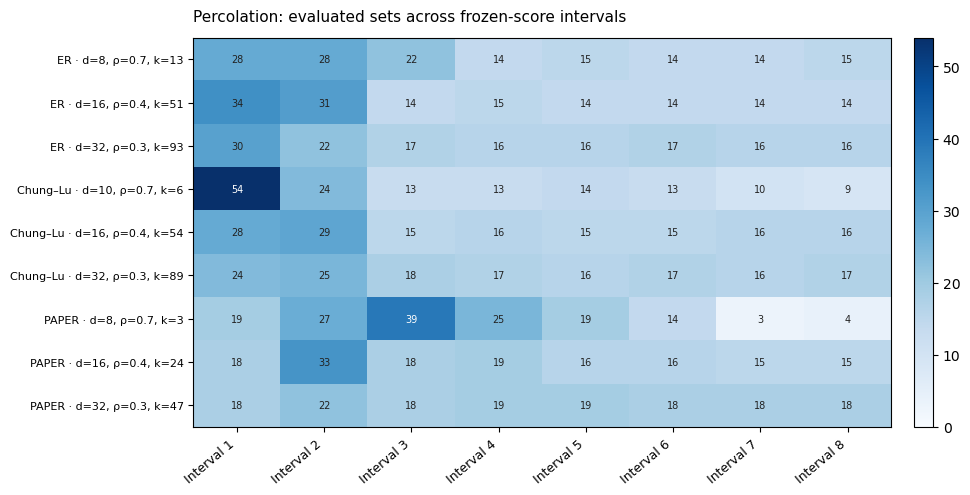

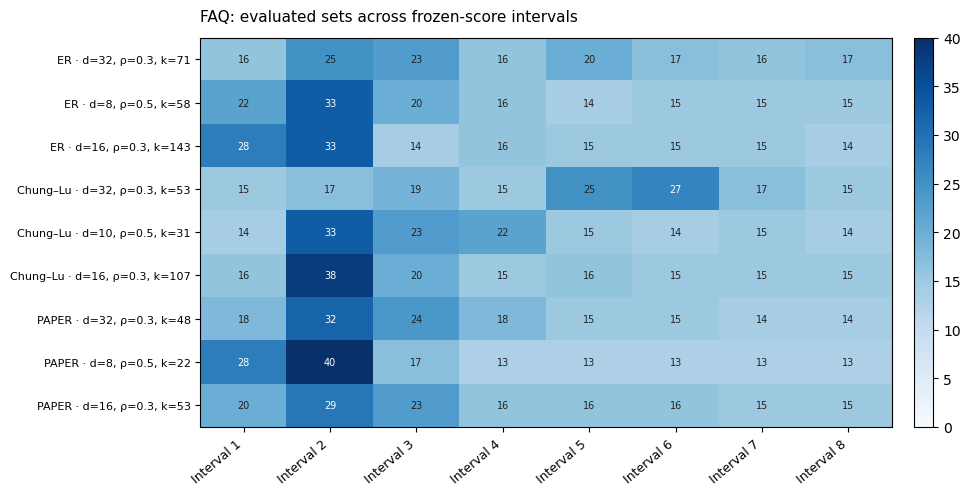

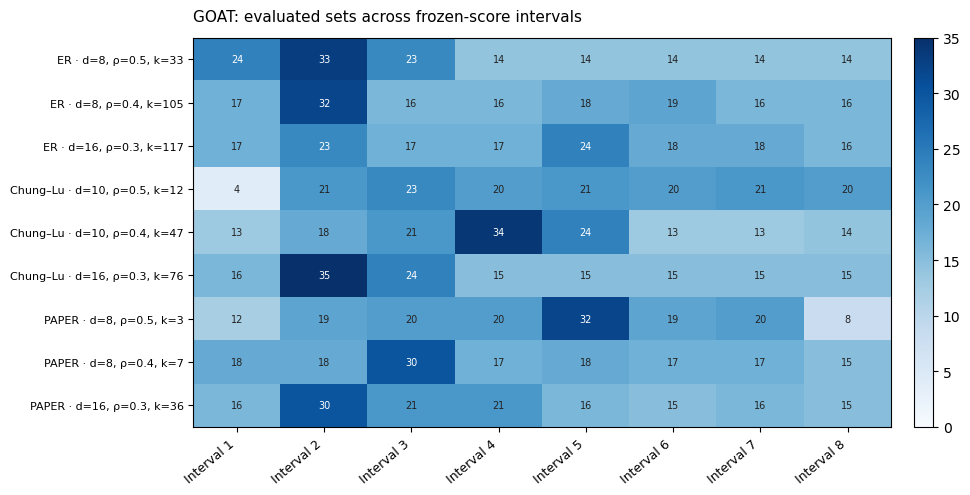

In [4]:
display(coverage[["panel", "algorithm", "sets", "random", "frozen_min", "frozen_max",
                  "frozen_span_ratio", "predicted_span_ratio"]])
occupied = data.coverage[data.coverage.available.gt(0)]
print("Occupied target intervals with no selected set:", int(occupied.selected.eq(0).sum()))
for algorithm in A.ALGORITHMS:
    show(A.plot_coverage(data, mean, algorithm), f"{algorithm}_score_coverage")

## 3. Own frozen score versus own saved selector

Each pair of columns shows the same sets and outcomes. The frozen score uses the
graph family's original frozen weights; the learned prediction uses the saved
selector for that exact cell, including the repaired PAPER percolation selector.
Normalization reproduces the original fresh pair's random pool. Grey y=x lines
on prediction panels check calibration; there are no fitted regression lines.

Random controls, score-range picks, contrasts, endpoints and hand rules share the
same three Bs. Full-bank correlation depends on our deliberate sampling design;
the random-control correlation describes the narrower uniform-set range.

### sparse er · percolation

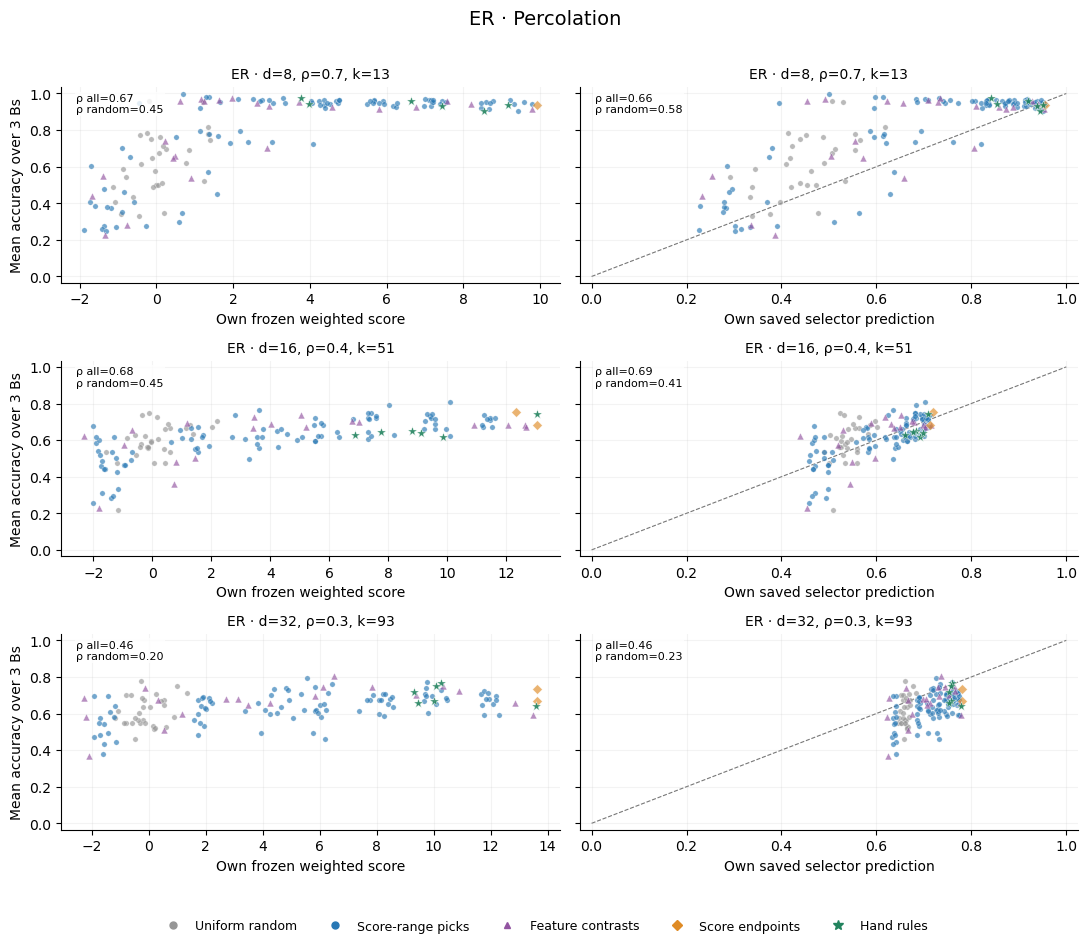

In [5]:
show(A.plot_synthetic_scores(mean, "sparse_er", "percolation"), "sparse_er_percolation_scores")

### sparse er · faq

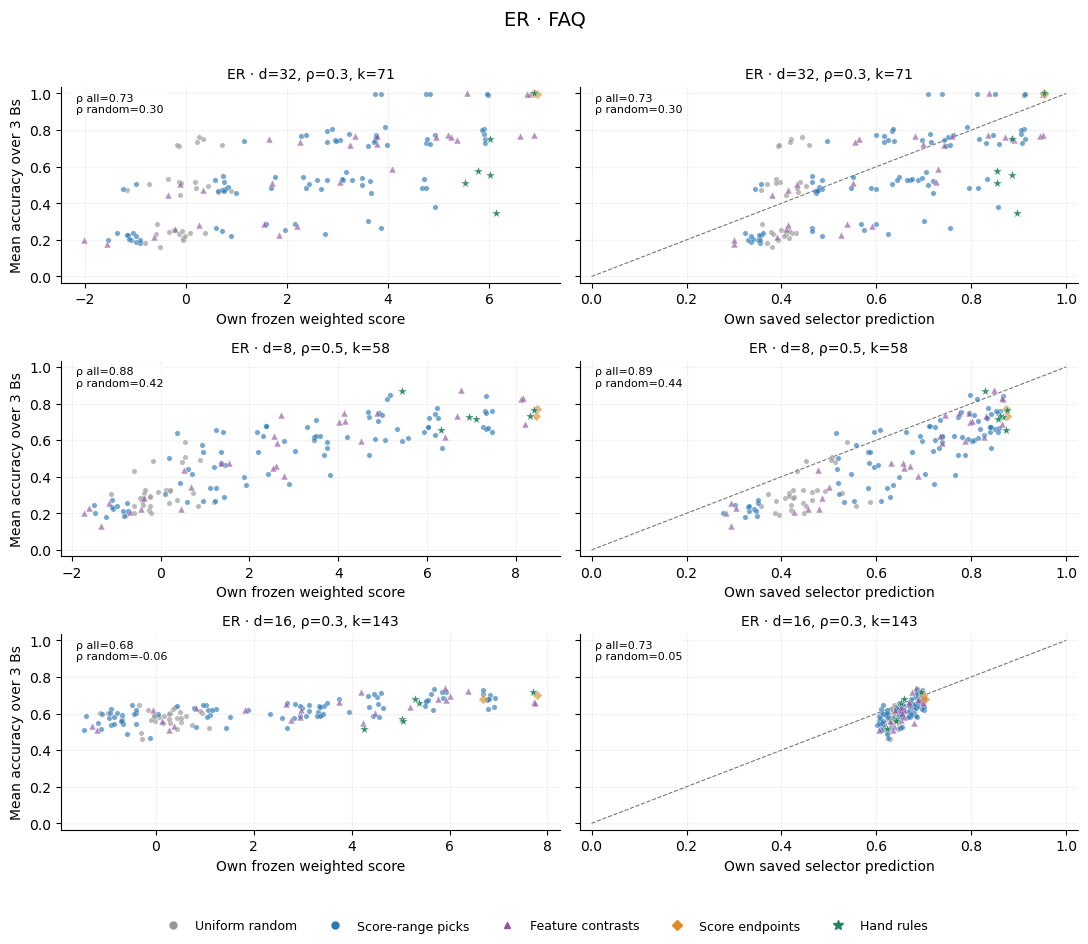

In [6]:
show(A.plot_synthetic_scores(mean, "sparse_er", "faq"), "sparse_er_faq_scores")

### sparse er · goat

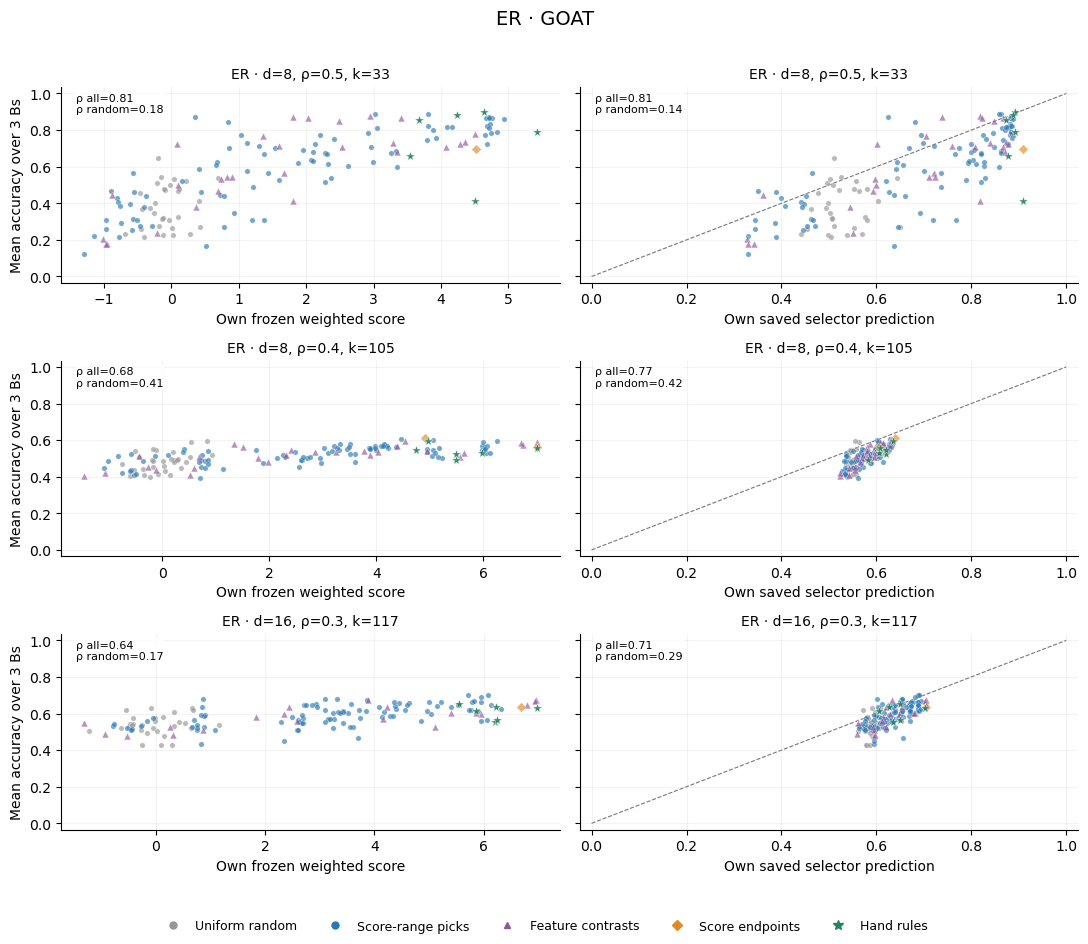

In [7]:
show(A.plot_synthetic_scores(mean, "sparse_er", "goat"), "sparse_er_goat_scores")

### chung lu · percolation

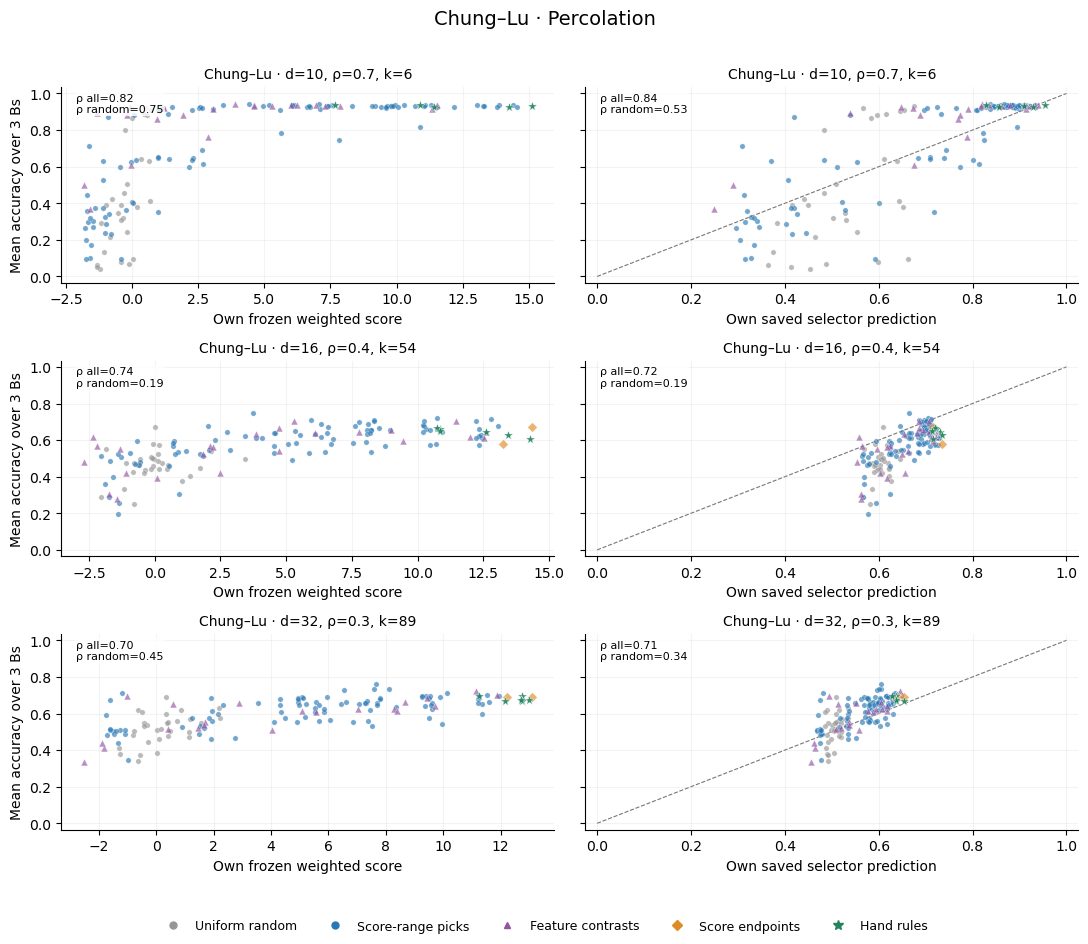

In [8]:
show(A.plot_synthetic_scores(mean, "chung_lu", "percolation"), "chung_lu_percolation_scores")

### chung lu · faq

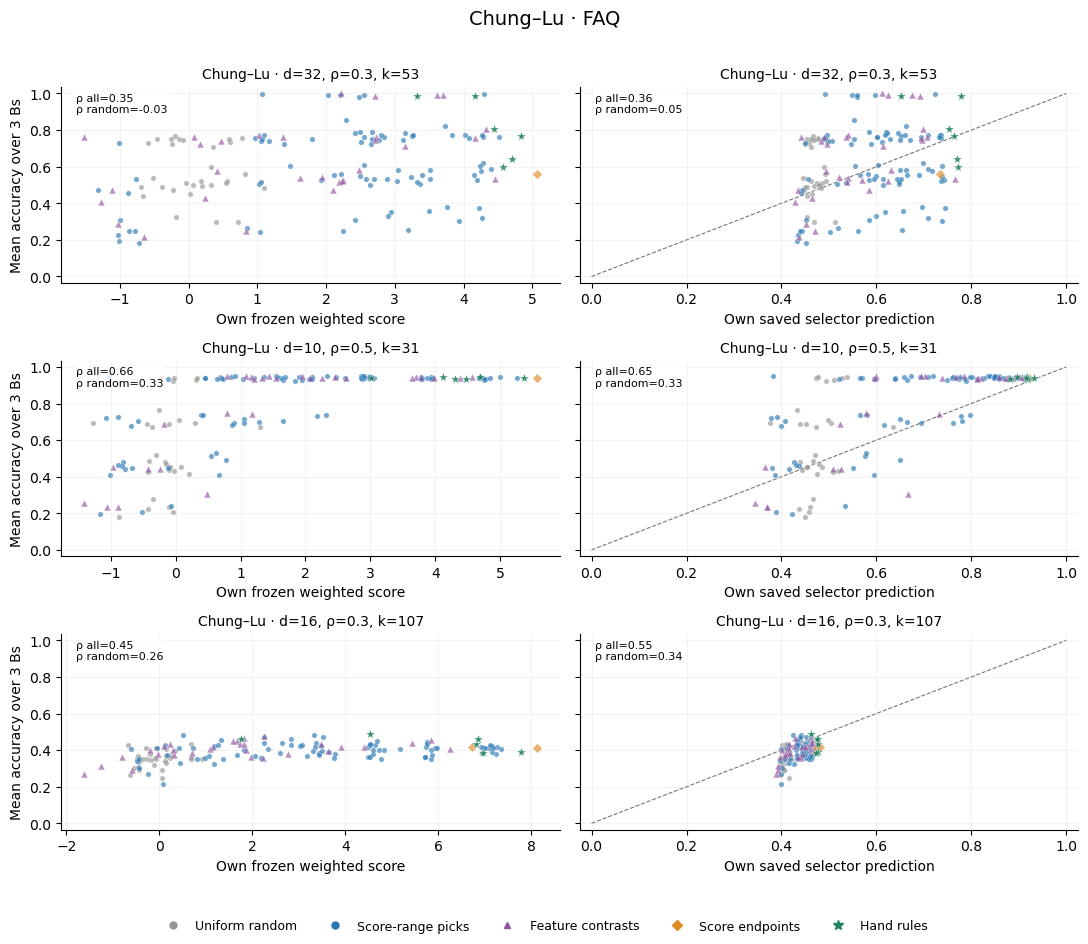

In [9]:
show(A.plot_synthetic_scores(mean, "chung_lu", "faq"), "chung_lu_faq_scores")

### chung lu · goat

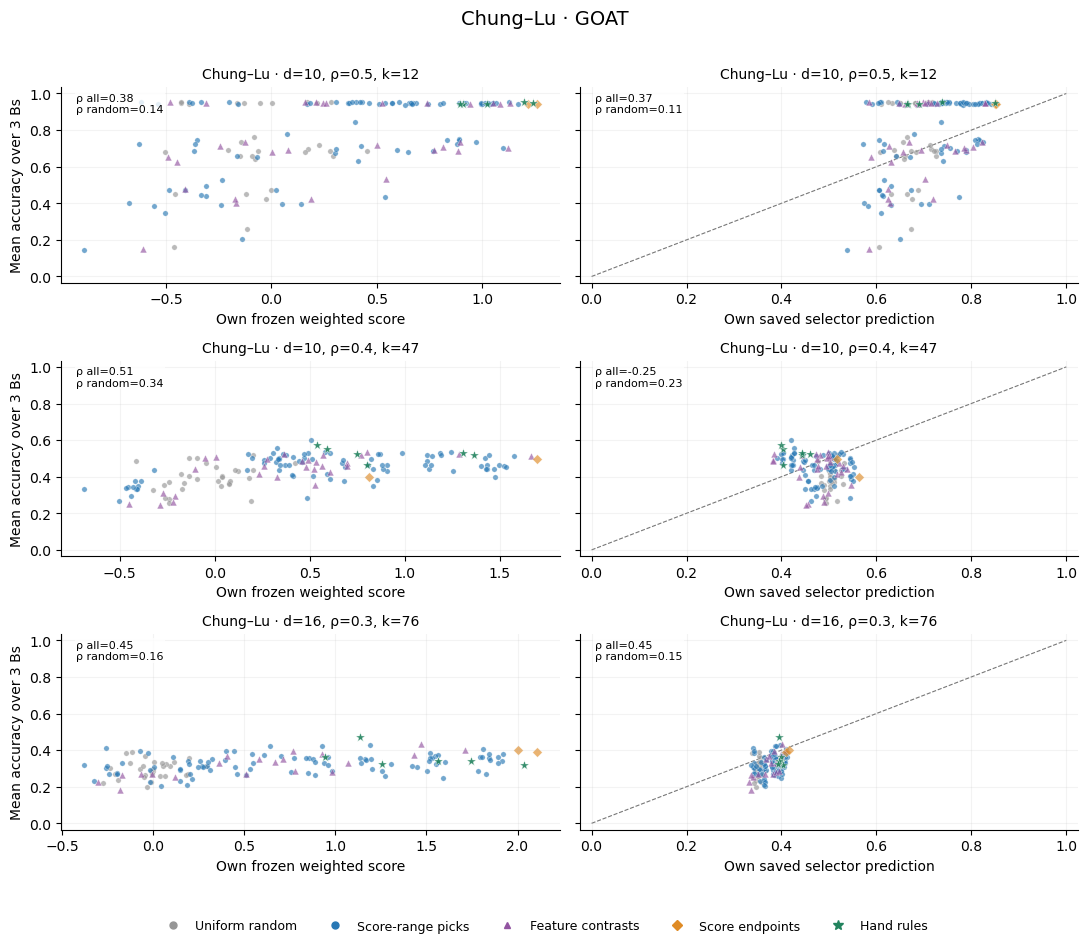

In [10]:
show(A.plot_synthetic_scores(mean, "chung_lu", "goat"), "chung_lu_goat_scores")

### paper pa · percolation

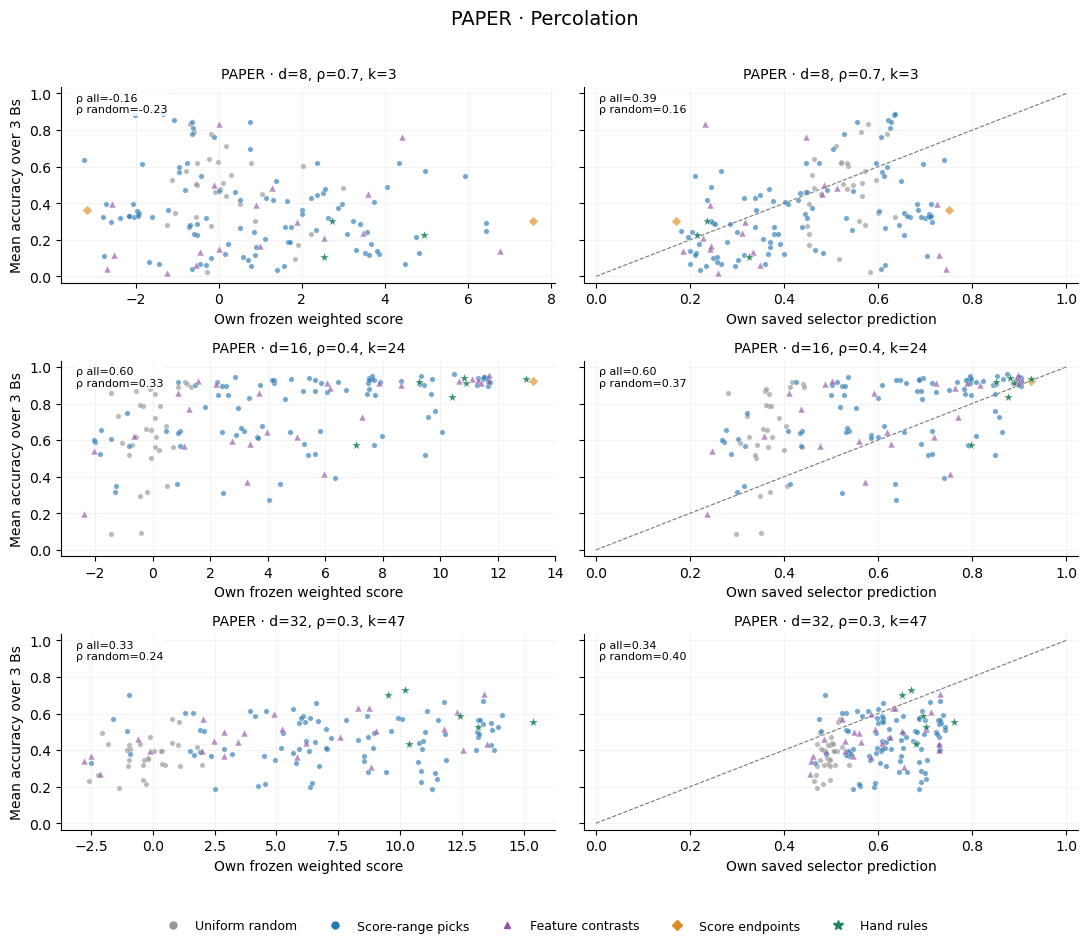

In [11]:
show(A.plot_synthetic_scores(mean, "paper_pa", "percolation"), "paper_pa_percolation_scores")

### paper pa · faq

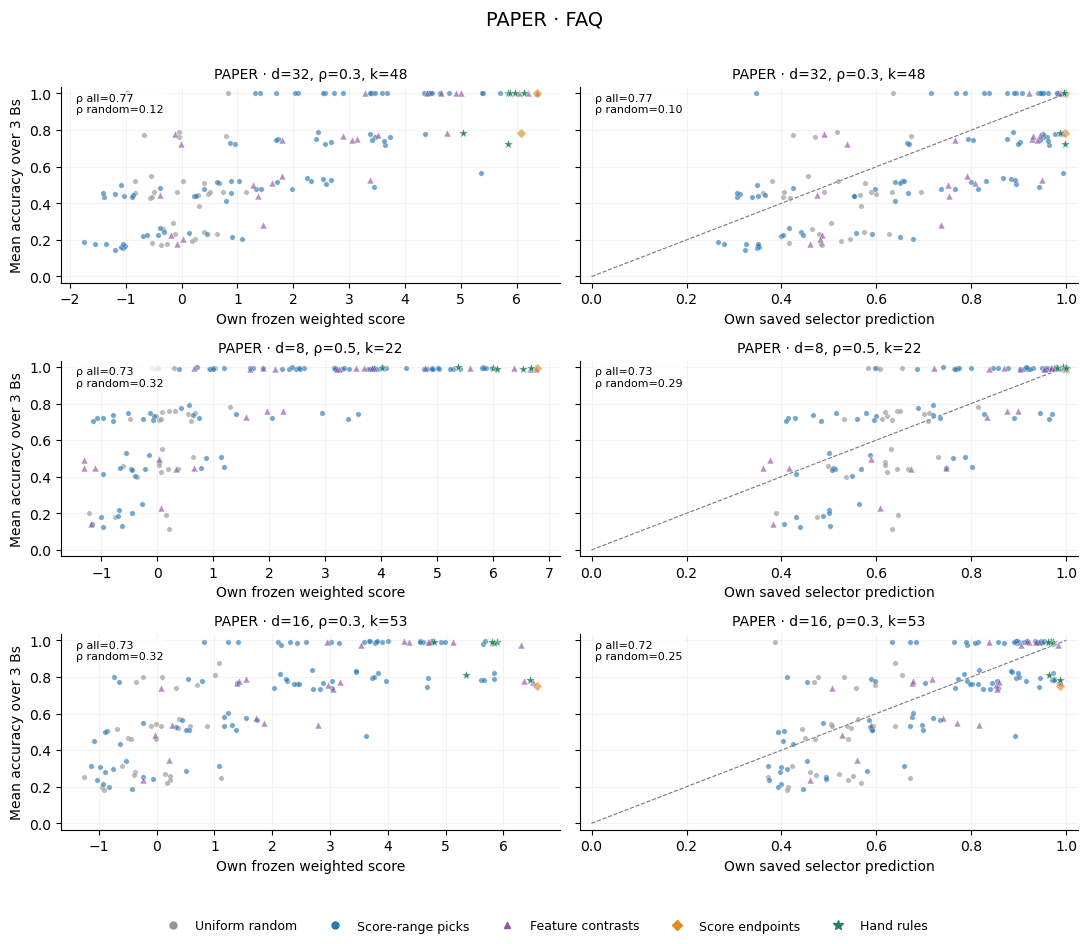

In [12]:
show(A.plot_synthetic_scores(mean, "paper_pa", "faq"), "paper_pa_faq_scores")

### paper pa · goat

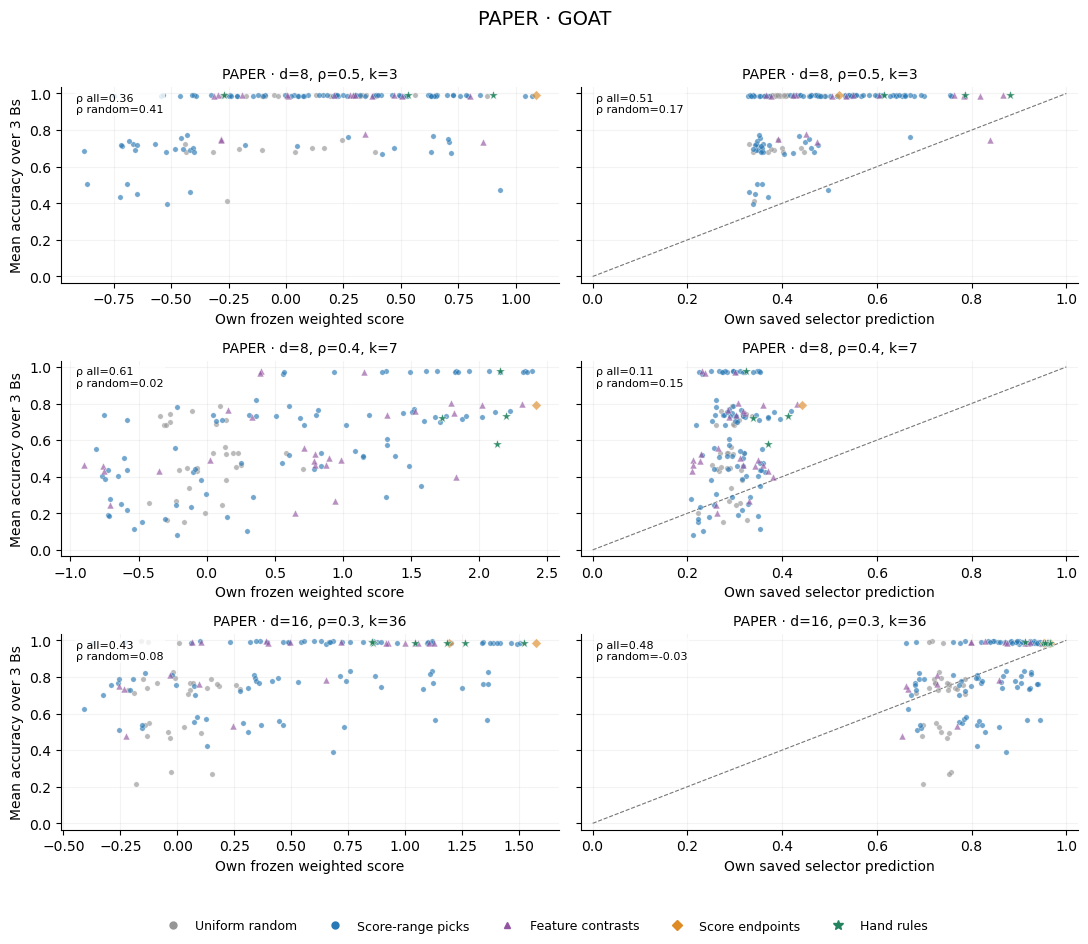

In [13]:
show(A.plot_synthetic_scores(mean, "paper_pa", "goat"), "paper_pa_goat_scores")

## 4. Does averaging across B clarify the random-set pattern?

Open grey circles are the original B; blue dots are the mean over the same three
Bs used throughout this notebook. The same 30 uniform sets are used in both views.
The x-axis and A do not change. A clearer pattern is a possible result, not an
assumption: compare the reported correlations cell by cell. Here repeated solver
randomness changes with B as in the collection design, so the comparison combines
B variability with its associated solver variability.

,rho_frozen_score_single,random_rho_frozen_score_single,rho_predicted_accuracy_single,random_rho_predicted_accuracy_single,rho_frozen_score_mean,random_rho_frozen_score_mean,rho_predicted_accuracy_mean,random_rho_predicted_accuracy_mean
algorithm,,,,,,,,
faq,0.524,0.264,0.559,0.233,0.728,0.297,0.727,0.291
goat,0.437,0.074,0.167,0.095,0.510,0.172,0.483,0.147
percolation,0.459,0.223,0.436,0.217,0.667,0.330,0.658,0.371


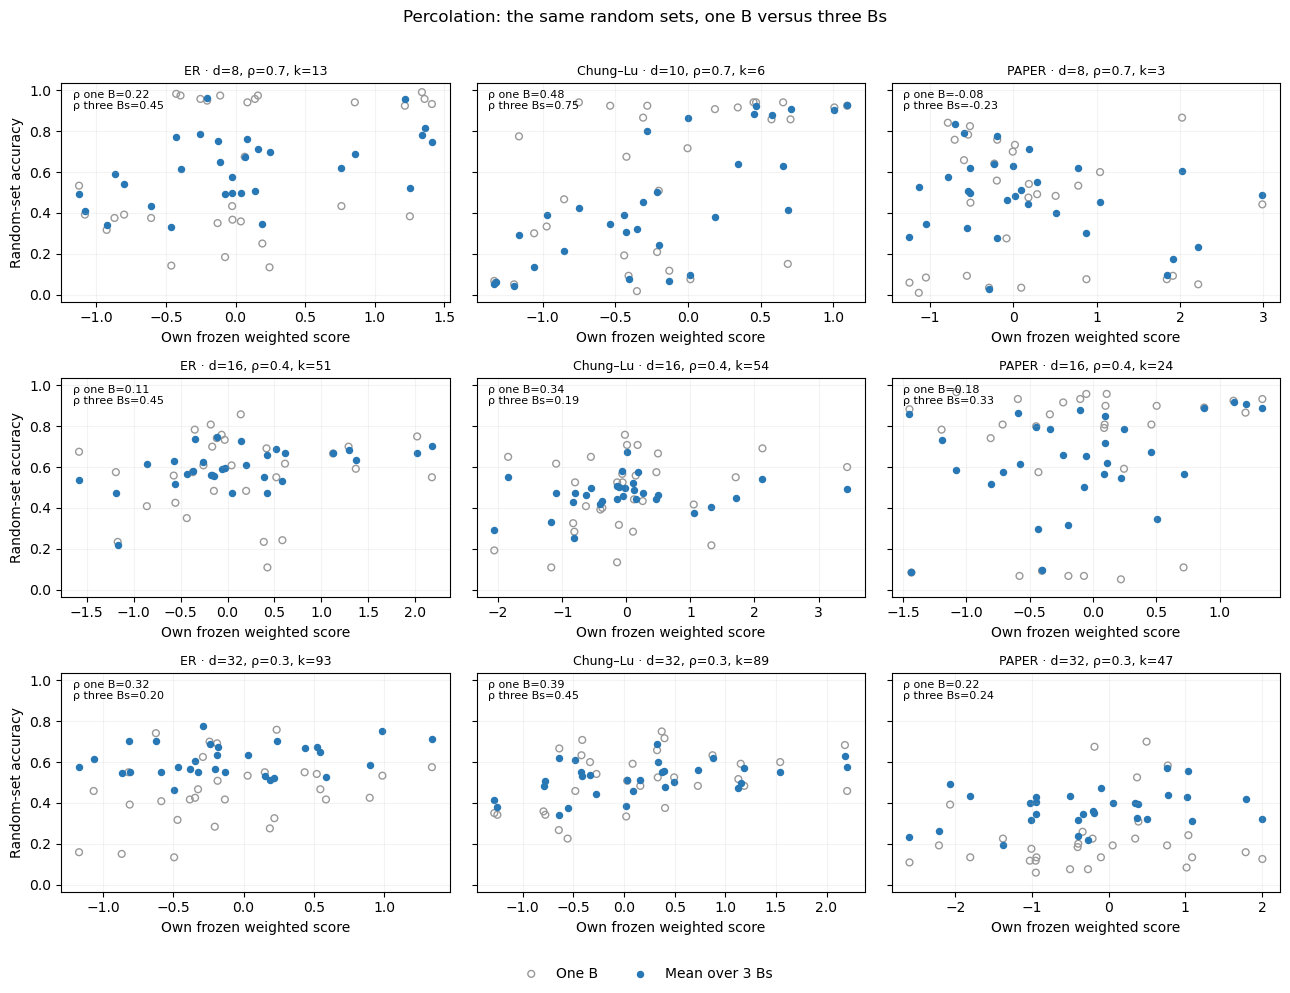

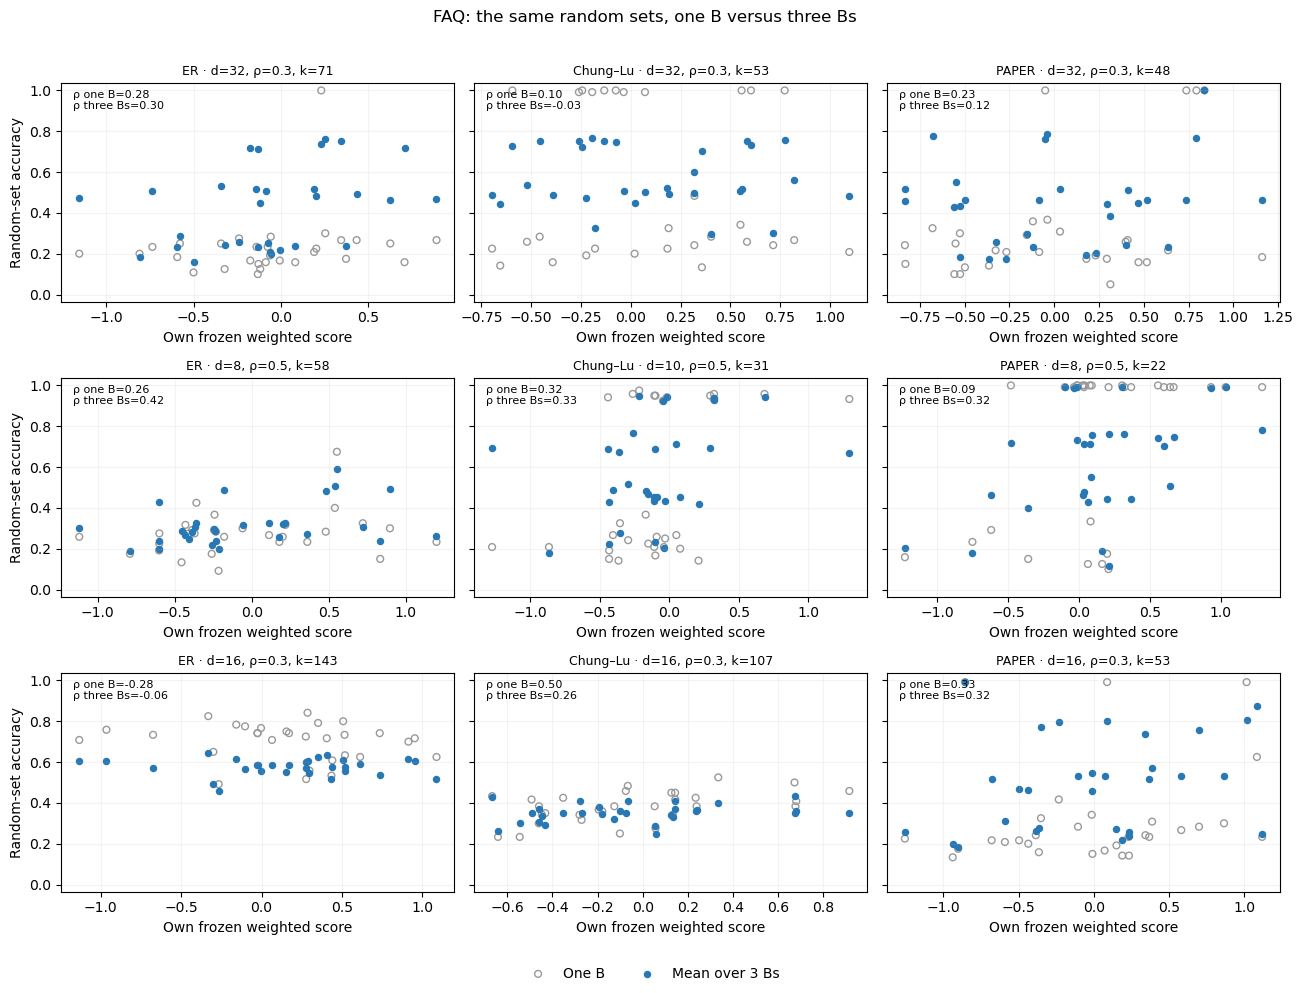

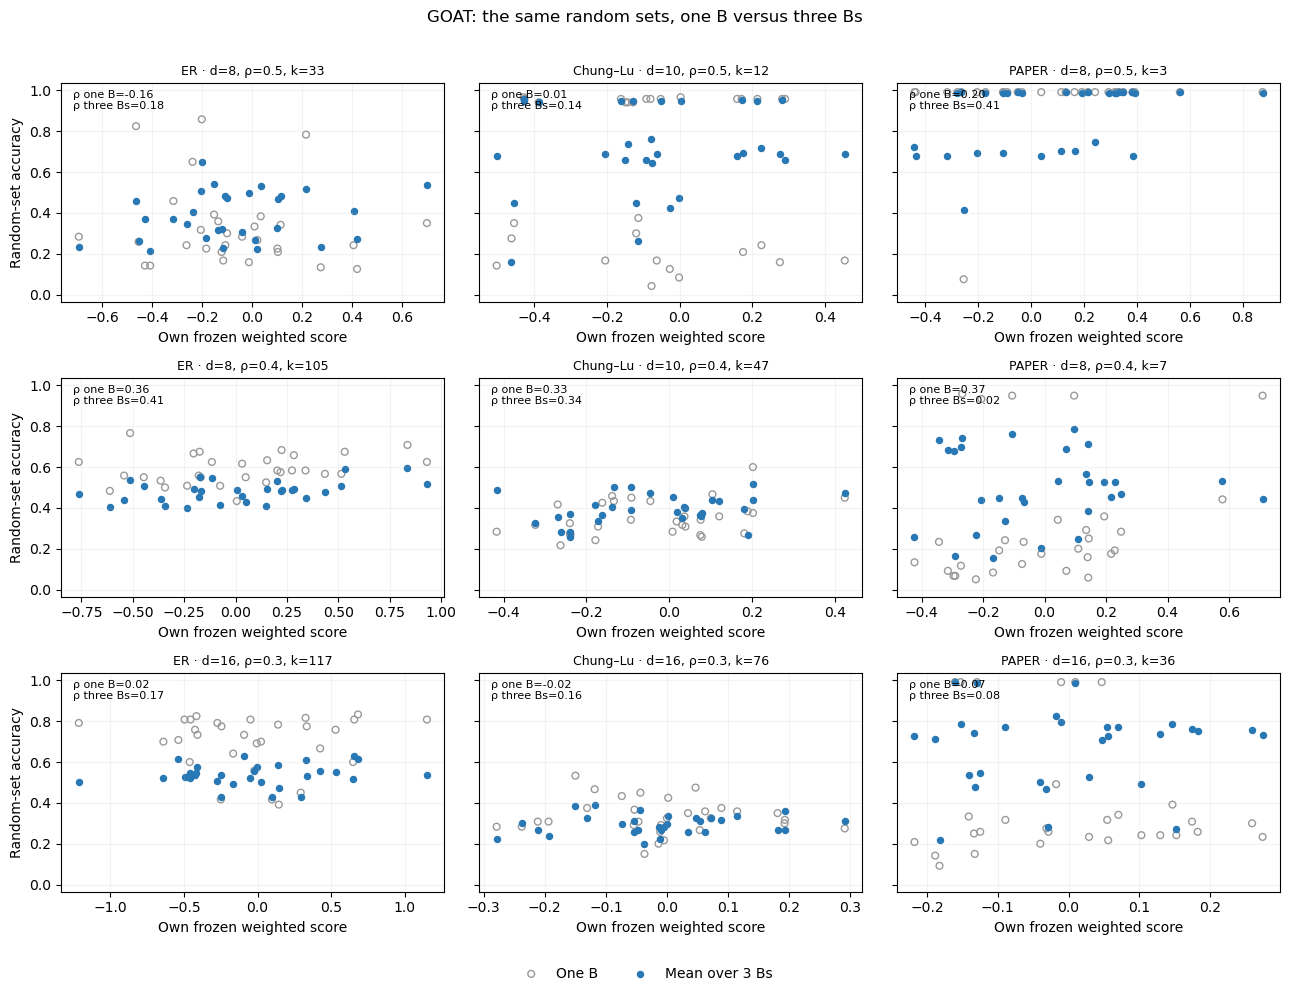

In [14]:
averaging = A.averaging_table(single, mean)
display(averaging.groupby("algorithm").median(numeric_only=True))
for algorithm in A.ALGORITHMS:
    show(A.plot_averaging(single, mean, algorithm), f"{algorithm}_random_one_vs_three_Bs")

## 5. Seed-selection performance and calibration

Pick each score's highest-scoring candidate in the same evaluated bank. The
guarded learned policy uses the saved source training-range flag; the unrestricted
policy is also shown. This guard is the one recorded during collection, not the
original search's pair-specific widening to cover rule sets. These results isolate
ranking in a fixed bank and do not reproduce the original optimizer's search.

The six named hand rules include clustered sets. Differences are relative to the
uniform controls' mean. The exported hindsight `oracle` is a descriptive upper
benchmark within this bank and is excluded from policy heatmaps. Each cell has
one A, so no uncertainty interval across independent A graphs is estimated here.

,panel,algorithm,rho_frozen_score,rho_predicted_accuracy,prediction_mae,prediction_bias,source_range_share
0,"ER · d=8, ρ=0.7, k=13",percolation,0.667,0.658,0.140,-0.113,1.000
1,"ER · d=16, ρ=0.4, k=51",percolation,0.677,0.686,0.064,-0.010,0.987
2,"ER · d=32, ρ=0.3, k=93",percolation,0.462,0.463,0.082,0.070,1.000
3,"ER · d=32, ρ=0.3, k=71",faq,0.731,0.734,0.150,0.060,1.000
4,"ER · d=8, ρ=0.5, k=58",faq,0.883,0.888,0.139,0.133,0.927
5,"ER · d=16, ρ=0.3, k=143",faq,0.682,0.728,0.049,0.043,1.000
6,"ER · d=8, ρ=0.5, k=33",goat,0.812,0.805,0.137,0.115,0.947
7,"ER · d=8, ρ=0.4, k=105",goat,0.684,0.767,0.067,0.066,0.973
8,"ER · d=16, ρ=0.3, k=117",goat,0.643,0.713,0.052,0.045,1.000
9,"Chung–Lu · d=10, ρ=0.7, k=6",percolation,0.825,0.844,0.126,-0.009,0.953


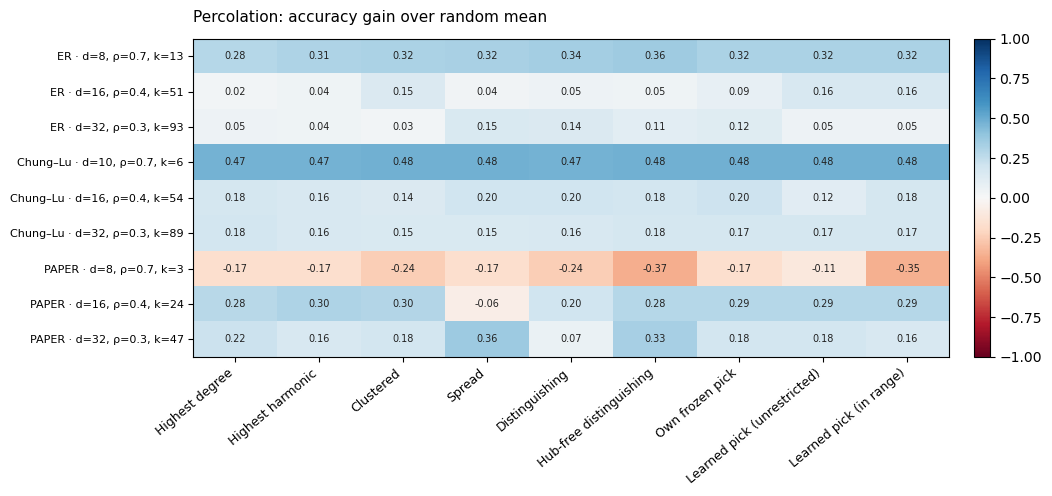

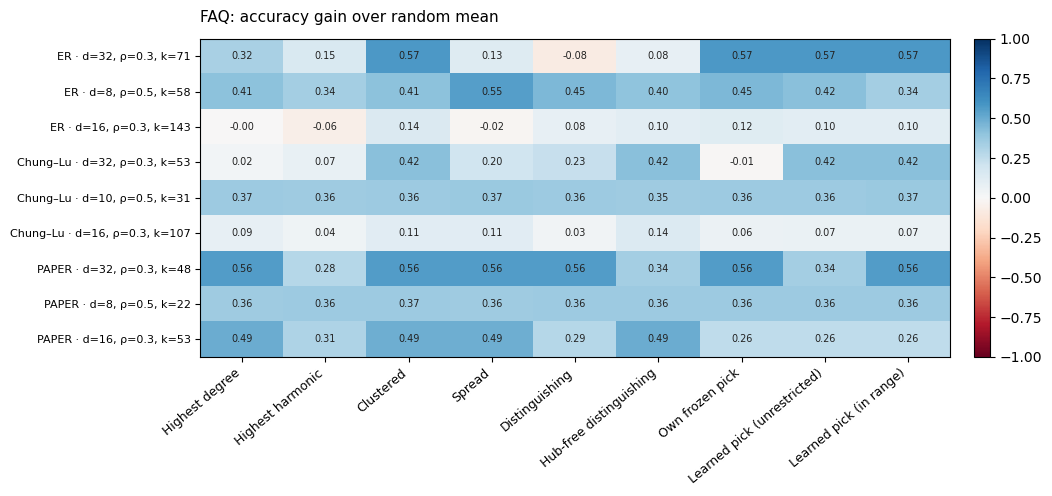

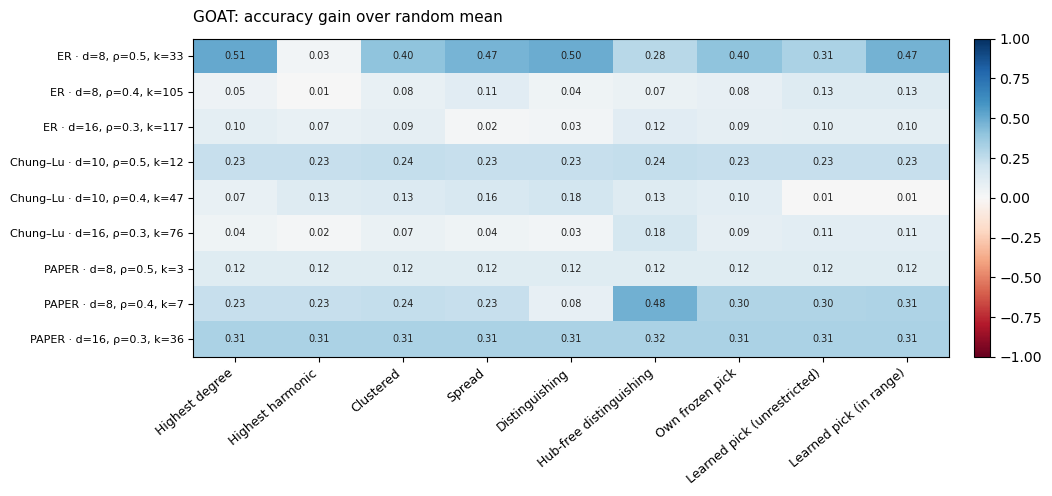

policy                                     frozen_own  learned_guarded  learned_mean  oracle
algorithm   panel                                                                           
faq         Chung–Lu · d=10, ρ=0.5, k=31        0.939            0.947         0.942   0.953
            Chung–Lu · d=16, ρ=0.3, k=107       0.411            0.419         0.419   0.486
            Chung–Lu · d=32, ρ=0.3, k=53        0.558            0.989         0.989   1.000
            ER · d=16, ρ=0.3, k=143             0.700            0.681         0.681   0.739
            ER · d=32, ρ=0.3, k=71              0.997            1.000         1.000   1.000
            ER · d=8, ρ=0.5, k=58               0.769            0.656         0.733   0.872
            PAPER · d=16, ρ=0.3, k=53           0.753            0.753         0.753   0.997
            PAPER · d=32, ρ=0.3, k=48           1.000            1.000         0.783   1.000
            PAPER · d=8, ρ=0.5, k=22            0.994            0.994         0.994   1.000
goat        Chung–Lu · d=10, ρ=0.4, k=47        0.497            0.400         0.400   0.603
            Chung–Lu · d=10, ρ=0.5, k=12        0.944            0.944         0.944   0.956
            Chung–Lu · d=16, ρ=0.3, k=76        0.389            0.403         0.403   0.472
            ER · d=16, ρ=0.3, k=117             0.628            0.636         0.636   0.703
            ER · d=8, ρ=0.4, k=105              0.564            0.614         0.614   0.614
            ER · d=8, ρ=0.5, k=33               0.789            0.858         0.697   0.897
            PAPER · d=16, ρ=0.3, k=36           0.986            0.986         0.986   0.994
            PAPER · d=8, ρ=0.4, k=7             0.794            0.800         0.794   0.978
            PAPER · d=8, ρ=0.5, k=3             0.992            0.992         0.992   0.992
percolation Chung–Lu · d=10, ρ=0.7, k=6         0.931            0.936         0.936   0.942
            Chung–Lu · d=16, ρ=0.4, k=54        0.669            0.642         0.581   0.747
            Chung–Lu · d=32, ρ=0.3, k=89        0.692            0.689         0.689   0.764
            ER · d=16, ρ=0.4, k=51              0.681            0.753         0.753   0.806
            ER · d=32, ρ=0.3, k=93              0.736            0.667         0.667   0.803
            ER · d=8, ρ=0.7, k=13               0.936            0.936         0.936   0.997
            PAPER · d=16, ρ=0.4, k=24           0.922            0.925         0.922   0.961
            PAPER · d=32, ρ=0.3, k=47           0.556            0.528         0.556   0.731
            PAPER · d=8, ρ=0.7, k=3             0.303            0.119         0.364   0.889

In [15]:
display(scores[["panel", "algorithm", "rho_frozen_score", "rho_predicted_accuracy",
                "prediction_mae", "prediction_bias", "source_range_share"]])
for algorithm in A.ALGORITHMS:
    show(A.plot_policy_summary(policies, algorithm), f"{algorithm}_policy_gains")
display(policies[policies.policy.isin(["frozen_own", "learned_mean", "learned_guarded", "oracle"])]
        .pivot(index=["algorithm", "panel"], columns="policy", values="accuracy"))

## 6. Which individual features track performance?

Each heatmap entry is a within-bank Spearman correlation across all unique seed
sets. Grey cells are undefined because a feature or the outcome is constant. All
core features use the algorithm's own definition, including distance-uniqueness
cap 2 for FAQ and cap 3 for percolation/GOAT. Coverage ≥2/≥3 and signature
collision features were computed on A during collection.

These correlations are exploratory and include intentionally constructed sets.
They do not establish that a feature adds value beyond degree; the saved contrasts
in the next section address that question more directly.

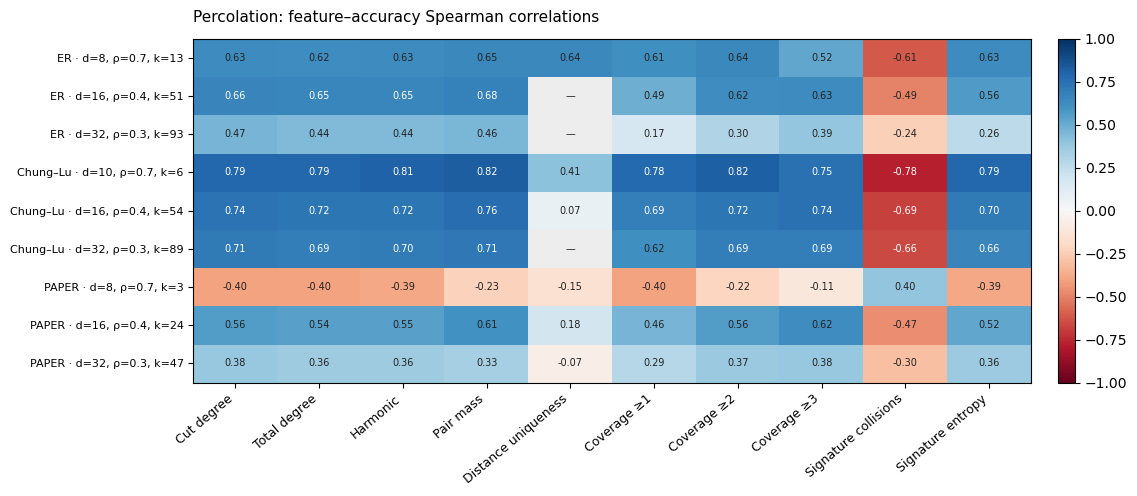

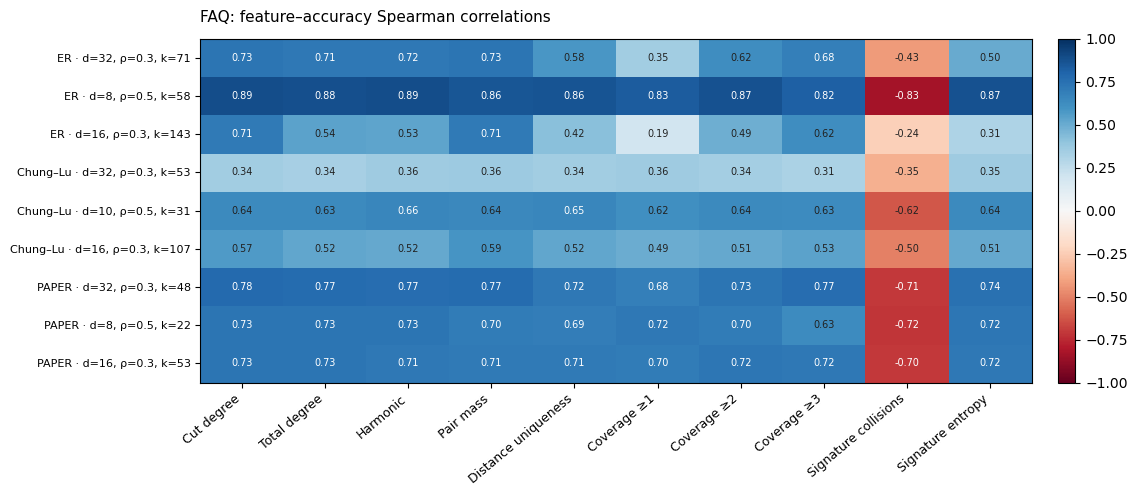

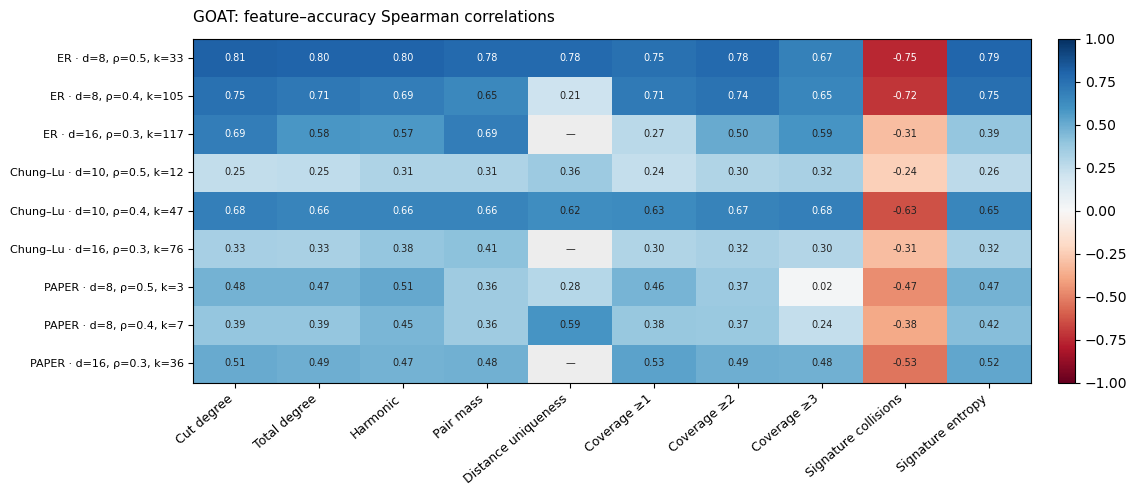

In [16]:
for algorithm in A.ALGORITHMS:
    show(A.plot_feature_summary(features, algorithm), f"{algorithm}_feature_correlations")

## 7. Feature contrasts at similar cut degree

These low/high contrasts were selected on A before matching was run. Plot only
pairs whose actual cut-degree difference is at most 0.25 random-pool SD; the full
table retains all pairs and their degree gaps. A point above zero means the
higher-feature set performed better. No significance intervals are fitted.

Degree matching is approximate, and other features can change simultaneously.
Contrasts within a bank can share sets and are not independent graph replicates.
For uniqueness, the x-axis follows the cap used to construct the contrast: cap 3
on shared real banks, and the cell's own cap on synthetics. The exported table
also gives the feature difference under the matching algorithm's cap.

contrasts  mean_accuracy_difference  median_accuracy_difference  fraction_positive  median_degree_gap_z
algorithm   feature                                                                                                            
faq         coverage           24                     0.018                      -0.006              0.375                0.072
            pair_mass          20                     0.004                       0.008              0.550                0.123
            uniqueness         24                    -0.021                      -0.004              0.333                0.097
goat        coverage           22                     0.005                      -0.010              0.409                0.082
            pair_mass          30                     0.006                      -0.001              0.467                0.141
            uniqueness         17                     0.124                       0.058              0.647                0.067
percolation coverage           19                     0.004                      -0.014              0.474                0.082
            pair_mass          19                     0.073                       0.058              0.684                0.184
            uniqueness         14                     0.084                       0.081              0.786                0.091

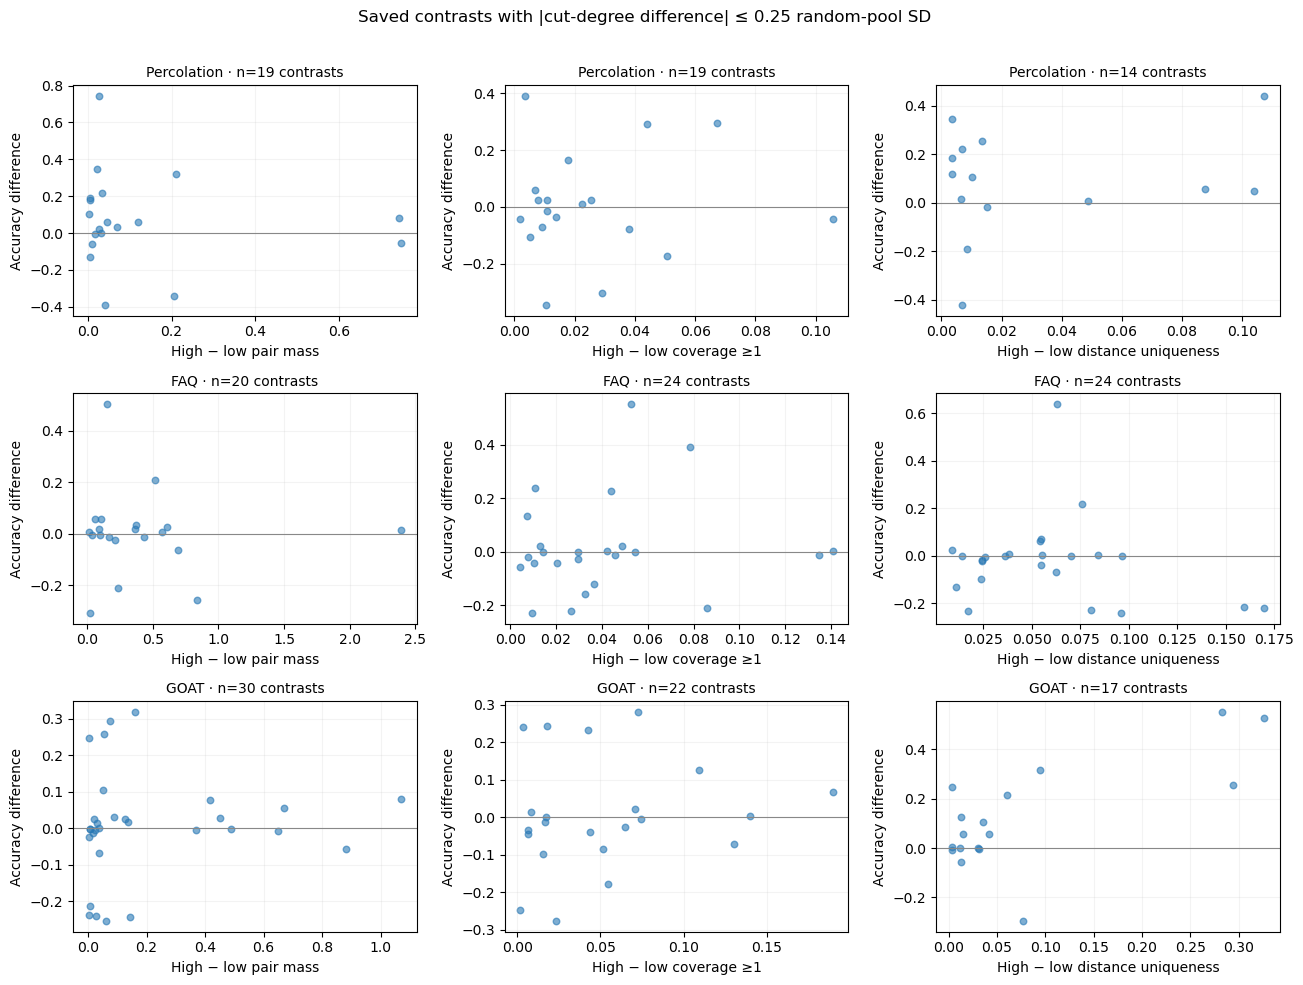

In [17]:
MAX_DEGREE_GAP_Z = 0.25
close = contrasts[contrasts.degree_z_gap.le(MAX_DEGREE_GAP_Z)]
display(close.groupby(["algorithm", "feature"]).agg(
    contrasts=("accuracy_delta", "size"), mean_accuracy_difference=("accuracy_delta", "mean"),
    median_accuracy_difference=("accuracy_delta", "median"),
    fraction_positive=("accuracy_delta", lambda s: s.gt(0).mean()),
    median_degree_gap_z=("degree_z_gap", "median")))
show(A.plot_contrasts(contrasts, MAX_DEGREE_GAP_Z), "degree_band_contrasts")

## 8. Solver convergence and sensitivity

All valid outcomes are retained in the main analyses: the experiment measures
performance under its fixed solver budget. Below, recompute correlations on the
subset of sets for which every evaluated FAQ/GOAT run converged. That subset can
be structurally different, so this is a diagnostic rather than a corrected result.
Percolation is omitted here because its `converged` flag means a complete matching,
not numerical optimizer convergence. Repeated solver runs or B draws do not
increase the number of independent A graphs.

In [18]:
display(convergence.groupby("algorithm")[["runs", "not_converged_runs"]].sum())
display(convergence.loc[convergence.not_converged_runs.gt(0)].drop(columns="bank_id"))

,runs,not_converged_runs
algorithm,,
faq,4050,49
goat,4050,25


,algorithm,panel,runs,not_converged_runs,not_converged_share,sets_all_runs_converged,sets_total,rho_frozen_all,rho_frozen_converged_subset,rho_learned_all,rho_learned_converged_subset
0,faq,"ER · d=32, ρ=0.3, k=71",450,1,0.002,149,150,0.731,0.732,0.734,0.735
1,faq,"ER · d=8, ρ=0.5, k=58",450,5,0.011,145,150,0.883,0.886,0.888,0.892
3,goat,"ER · d=8, ρ=0.5, k=33",450,11,0.024,139,150,0.812,0.814,0.805,0.807
5,goat,"ER · d=16, ρ=0.3, k=117",450,1,0.002,149,150,0.643,0.641,0.713,0.711
6,faq,"Chung–Lu · d=32, ρ=0.3, k=53",450,1,0.002,149,150,0.355,0.359,0.356,0.360
7,faq,"Chung–Lu · d=10, ρ=0.5, k=31",450,41,0.091,111,150,0.663,0.697,0.654,0.691
9,goat,"Chung–Lu · d=10, ρ=0.5, k=12",450,2,0.004,148,150,0.377,0.368,0.374,0.368
10,goat,"Chung–Lu · d=10, ρ=0.4, k=47",450,1,0.002,149,150,0.510,0.511,-0.254,-0.261
11,goat,"Chung–Lu · d=16, ρ=0.3, k=76",450,1,0.002,149,150,0.446,0.443,0.448,0.447
12,faq,"PAPER · d=32, ρ=0.3, k=48",450,1,0.002,149,150,0.771,0.771,0.770,0.770


## 9. Exports and interpretation

Every displayed figure is exported as PNG and PDF. CSV tables contain the full
inventory, per-seed means, score diagnostics, feature correlations, policy picks,
individual source-model diagnostics, contrasts and convergence results. The
collector's raw files and saved model snapshots remain the inputs for this notebook.

Read ranking, calibration and selection performance separately. A high correlation
does not guarantee a good top pick, and a useful ranking need not predict absolute
accuracy well. The broad bank deliberately changes the sampled feature distribution.
Generalization claims require additional A graphs and untouched real pairs.

In [19]:
A.export_tables(EXPORT,
    inventory=A.inventory(data), per_seed_mean=mean, score_coverage=coverage,
    sampling_intervals=data.coverage,
    score_diagnostics=scores, feature_correlations=features, policy_results=policies,
    individual_sources=sources, degree_contrasts=contrasts, convergence=convergence,
    overview=summary.reset_index(), averaging=averaging)
print("CSV tables:", EXPORT)
print("PNG/PDF figures:", FIGURES)

CSV tables: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_analysis/synthetic
PNG/PDF figures: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_analysis/synthetic/figures
